# spec-trait Evaluation

Analysis of runtime performance, compile time, and binary size for `spec!`/`when` vs alternatives:
- **spec**: compile-time specialization via `spec!`/`when` macros
- **naive**: generic fallback (no specialization)
- **runtime_typeid**: `TypeId`-based runtime branching

## Examples
| # | Operation | Key specialization |
|---|-----------|--------------------|
| ex01 | Histogram | u8 array[256] vs HashMap |
| ex02 | Set intersection | u8 bitmap[256] vs HashSet |
| ex03 | Contains search | u8 memchr SIMD |
| ex04 | Sort | u8 counting sort |
| ex05 | Distinct count | u8 bitmap[256] vs HashSet |
| ex06 | Bulk serialize | u8 zero-copy |
| ex07 | Dedup | u8 bitmap vs HashSet |
| ex08 | Count value | u8 memchr_iter vs filter |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
from pathlib import Path

# ── Publication-quality defaults ──────────────────────────────────────
sns.set_theme(style="ticks", font_scale=1.15, rc={
    "axes.linewidth":    0.8,
    "axes.titlesize":    12,
    "axes.titleweight":  "bold",
    "axes.labelsize":    11,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
    "legend.fontsize":   9,
    "legend.frameon":    True,
    "legend.edgecolor":  "0.8",
    "legend.fancybox":   True,
    "figure.dpi":        120,
    "savefig.dpi":       300,
    "savefig.bbox":      "tight",
    "font.family":       "sans-serif",
})

RESULTS = Path("../results")

# ── Approach identifiers ──────────────────────────────────────────────
APPROACH_ORDER = ["spec", "runtime_typeid", "naive"]

# Colorblind-safe Okabe-Ito palette
APPROACH_COLORS = {
    "spec":            "#0072B2",   # blue
    "runtime_typeid":  "#D55E00",   # vermillion
    "naive":           "#CC79A7",   # pink
}

APPROACH_LABELS = {
    "spec":            "spec! (ours)",
    "runtime_typeid":  "TypeId",
    "naive":           "Naive",
}

APPROACH_MARKERS = {
    "spec":            "o",
    "runtime_typeid":  "s",
    "naive":           "D",
}

APPROACH_HATCHES = {
    "spec":            "",
    "runtime_typeid":  "//",
    "naive":           "xx",
}

# ── Shared constants ──────────────────────────────────────────────────
LW       = 1.8        # line width
MS       = 5          # marker size
BAND_A   = 0.15       # fill_between alpha
LEG_FS   = 9          # legend font size
SAVE_KW  = dict(bbox_inches="tight", dpi=300)

def _label(a):
    """Return display label for an approach key."""
    return APPROACH_LABELS.get(a, a)

def _color(a):
    return APPROACH_COLORS.get(a, "gray")

def _marker(a):
    return APPROACH_MARKERS.get(a, "o")

def make_grid(n, per_w=4.2, per_h=3.6):
    """Create a 2-row subplot grid for *n* examples."""
    ncols = (n + 1) // 2
    fig, axes = plt.subplots(2, ncols,
                             figsize=(per_w * ncols, per_h * 2),
                             constrained_layout=True)
    return fig, axes.flatten()

def finish_grid(fig, axes, n, path=None):
    """Hide unused axes, despine, and optionally save."""
    for i in range(n, len(axes)):
        axes[i].set_visible(False)
    for ax in axes[:n]:
        sns.despine(ax=ax)
    if path is not None:
        fig.savefig(path, **SAVE_KW)

def style_log_x(ax):
    """Apply log-2 x axis with scalar tick labels."""
    ax.set_xscale("log", base=2)
    ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.ticklabel_format(axis="x", style="plain")

## 1. Runtime Performance

In [2]:
rt = pd.read_csv(RESULTS / "runtime.csv")
rt["size"] = pd.to_numeric(rt["size"], errors="coerce")
rt = rt.dropna(subset=["size", "median_ns"])
rt["median_us"] = rt["median_ns"] / 1000.0 # from nanoseconds to microseconds

examples = sorted(rt["example"].unique())
n_ex = len(examples)
rt.head()

,example,operation,group,approach,size,mean_ns,mean_se_ns,mean_ci_lower_ns,mean_ci_upper_ns,median_ns,median_se_ns,median_ci_lower_ns,median_ci_upper_ns,slope_ns,slope_se_ns,slope_ci_lower_ns,slope_ci_upper_ns,std_dev_ns,median_abs_dev_ns,median_us
0,ex01,extend,ex01_extend,naive,1024,3229.690111,5.360521,3219.882092,3240.870496,3226.707720,3.359888,3220.799993,3233.136330,3215.526307,6.543672,3204.160368,3229.704169,53.826907,36.201934,3.226708
1,ex01,extend,ex01_extend,naive,128,415.667241,0.251595,415.163620,416.149125,415.993335,0.283175,415.341166,416.402927,415.818964,0.278075,415.290888,416.382232,2.522190,1.727969,0.415993
2,ex01,extend,ex01_extend,naive,16,56.936107,0.372290,56.423627,57.791373,56.418441,0.068534,56.312779,56.567371,56.822927,0.257788,56.434897,57.412047,3.751509,0.628132,0.056418
3,ex01,extend,ex01_extend,naive,2048,6443.269778,8.140974,6425.956665,6457.877483,6446.880775,4.637572,6440.668790,6459.756995,6448.604998,4.813631,6439.208204,6458.154950,81.820029,38.015482,6.446881
4,ex01,extend,ex01_extend,naive,256,820.500966,0.965667,818.487923,822.269526,822.046010,0.494511,821.137481,823.072236,822.048318,0.752599,820.567927,823.524845,9.697965,6.589638,0.822046


### Perche' usiamo la mediana e dividiamo per 1000?

Usiamo `median_ns` perche' la **mediana** e' piu' robusta della media rispetto a outlier e rumore sperimentale. Nei benchmark alcune misure possono essere disturbate da effetti esterni come scheduling del sistema operativo, cache, turbo boost o processi in background: la mediana rappresenta meglio il **tempo tipico** osservato.

La divisione per `1000.0` serve solo a cambiare unita' di misura: i dati nel CSV sono in **nanosecondi (`ns`)**, mentre nei grafici vogliamo mostrare **microsecondi (`µs`)** per avere valori piu' leggibili.

$$1\,\mu s = 1000\,ns$$

Quindi:

- `median_ns` = tempo mediano in nanosecondi
- `median_us = median_ns / 1000.0` = stesso valore espresso in microsecondi

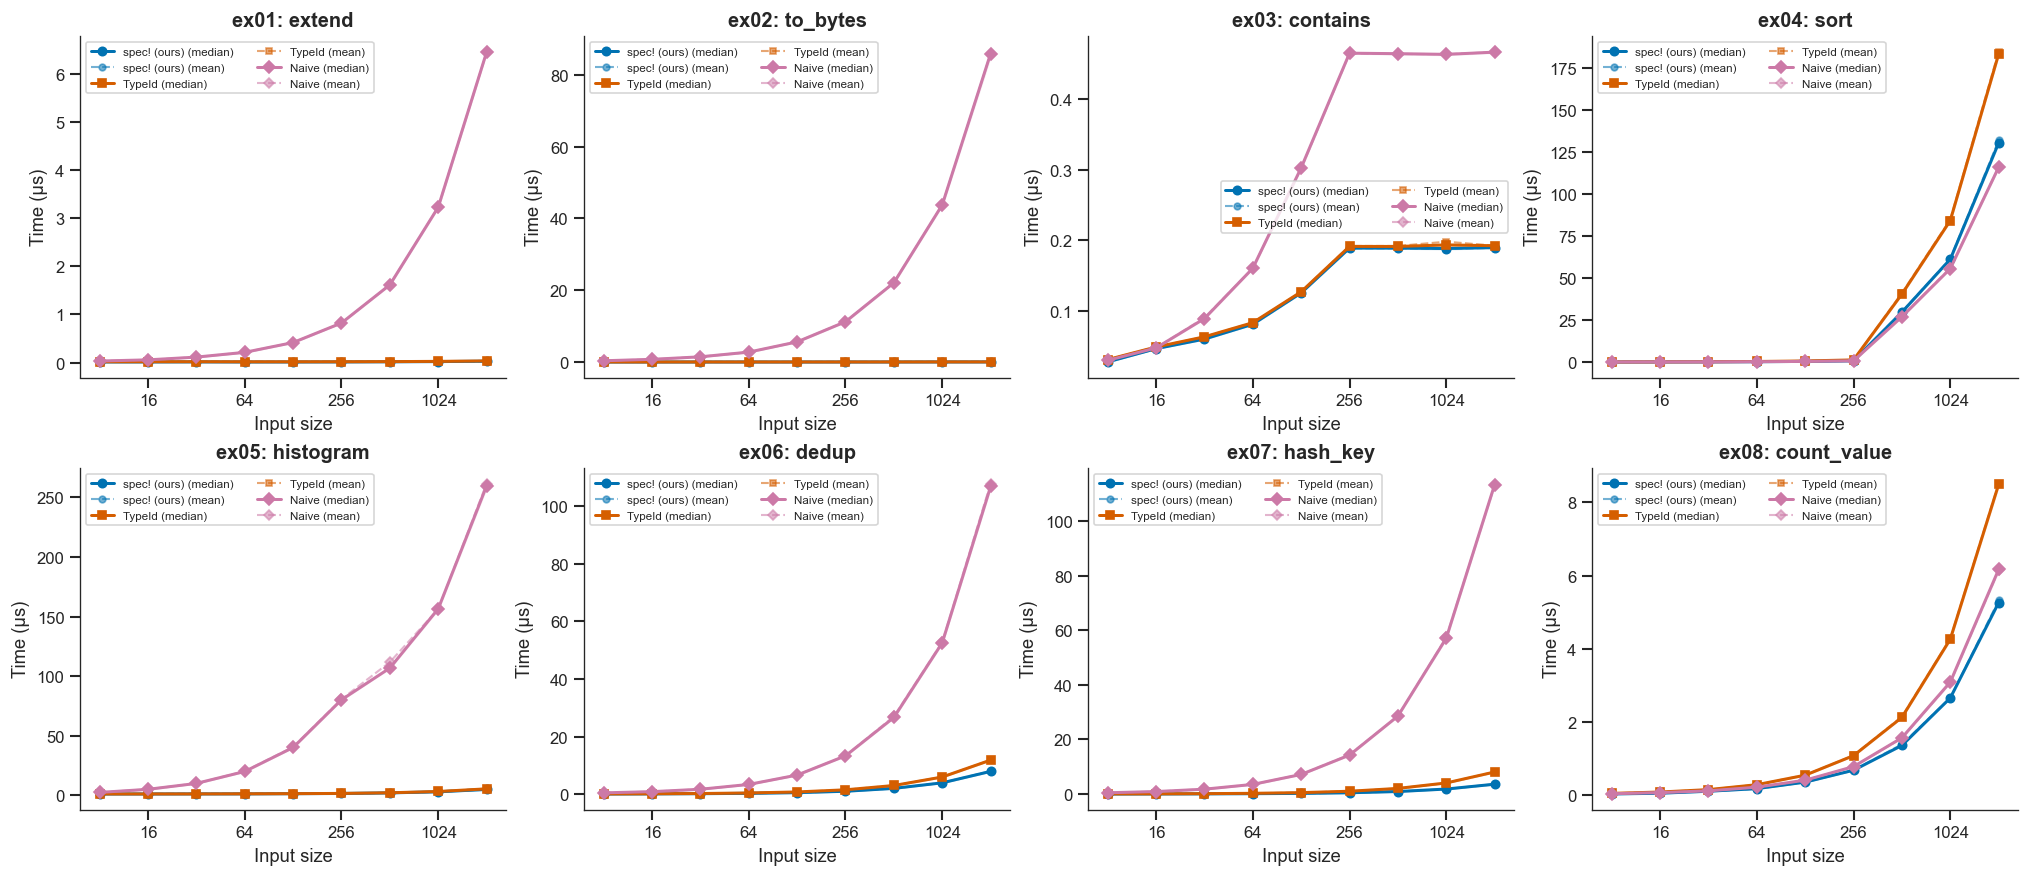

In [3]:
# Mean vs Median comparison — solid = median, dashed = mean, band = median 95 % CI
has_mean = "mean_ns" in rt.columns

if has_mean:
    rt["mean_us"] = rt["mean_ns"] / 1000.0

    # Pre-compute median CI in µs (if available)
    has_med_ci = {"median_ci_lower_ns", "median_ci_upper_ns"}.issubset(rt.columns)
    if has_med_ci:
        rt["med_ci_lo_us"] = rt["median_ci_lower_ns"] / 1000.0
        rt["med_ci_hi_us"] = rt["median_ci_upper_ns"] / 1000.0

    fig, axes = make_grid(n_ex)

    for idx, ex in enumerate(examples):
        ax = axes[idx]
        sub = rt[rt["example"] == ex]
        op = sub["operation"].iloc[0]
        for a in APPROACH_ORDER:
            d = sub[sub["approach"] == a].sort_values("size")
            if d.empty:
                continue
            c, m = _color(a), _marker(a)
            ax.plot(d["size"], d["median_us"],
                    marker=m, ms=MS, lw=LW, color=c,
                    label=f"{_label(a)} (median)")
            ax.plot(d["size"], d["mean_us"],
                    marker=m, ms=MS-1, lw=LW*0.7, ls="--", color=c, alpha=0.55,
                    label=f"{_label(a)} (mean)")
            if has_med_ci:
                ax.fill_between(d["size"], d["med_ci_lo_us"], d["med_ci_hi_us"],
                                alpha=BAND_A, color=c)
        ax.set_title(f"{ex}: {op}")
        ax.set_xlabel("Input size")
        ax.set_ylabel("Time (µs)")
        style_log_x(ax)
        ax.legend(fontsize=7, ncol=2)

    finish_grid(fig, axes, n_ex, RESULTS / "mean_vs_median.pdf")
    plt.show()
else:
    print("mean_ns column not found — only median is available.")

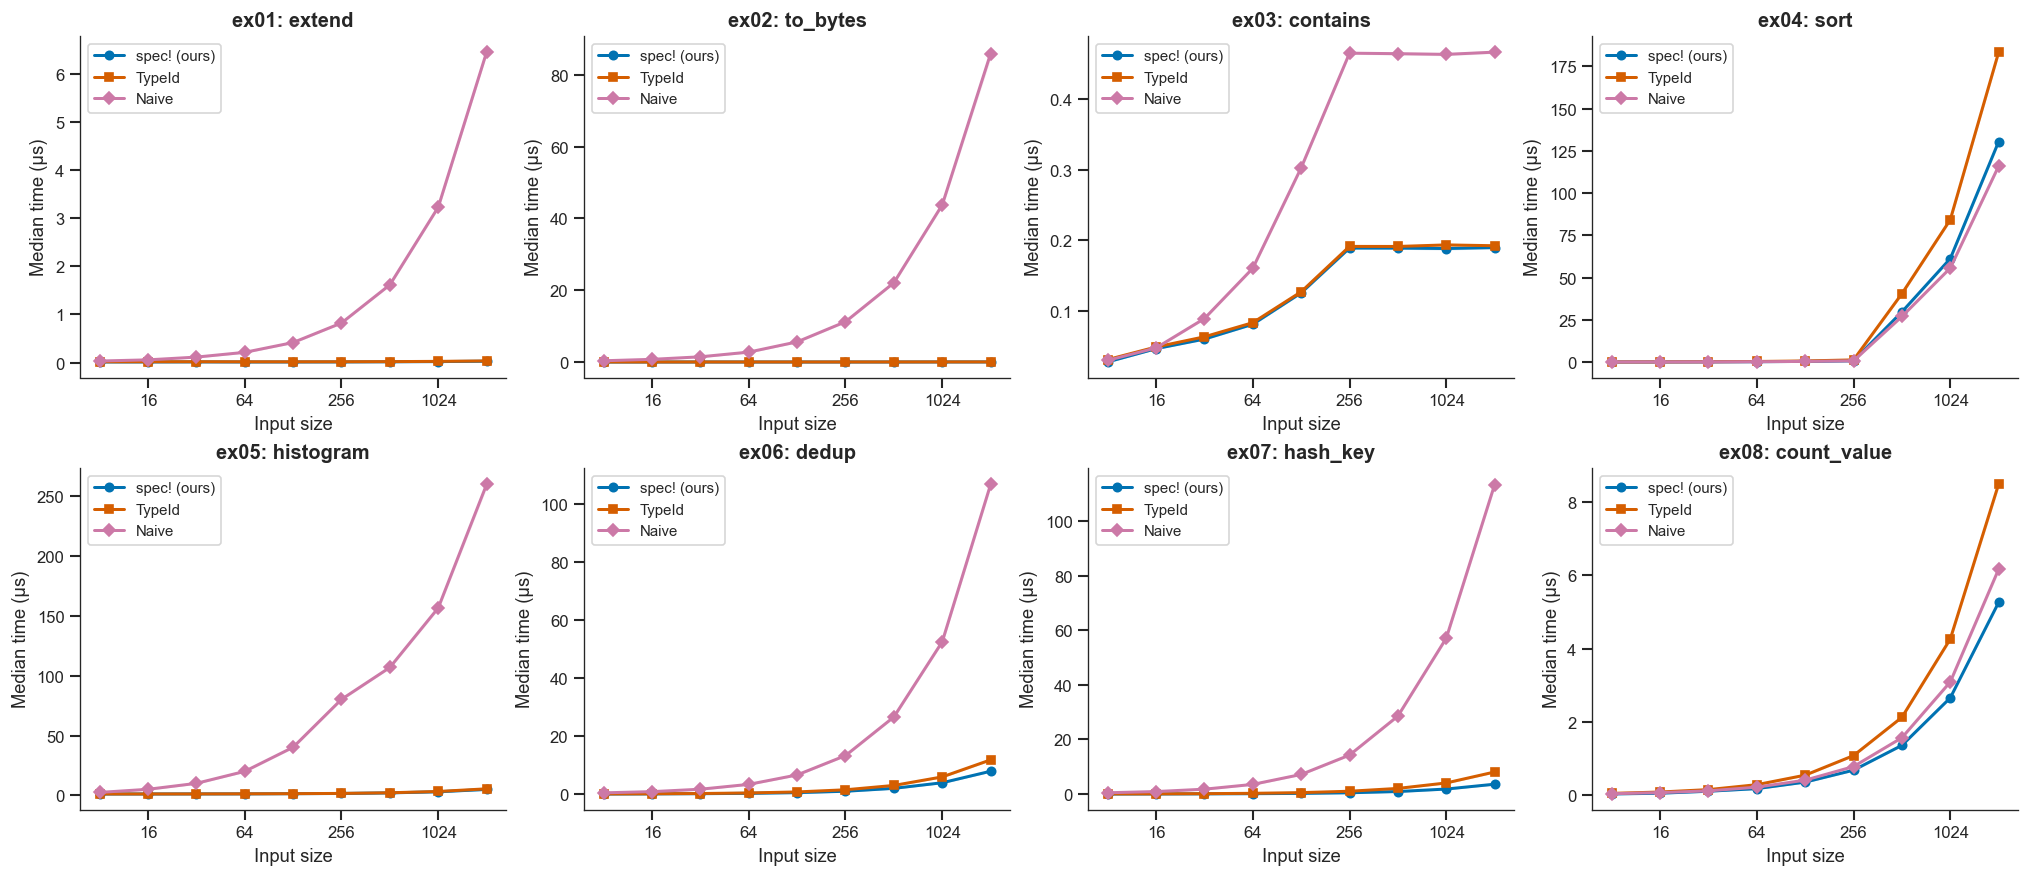

In [ ]:
# Runtime overview — median ± 95 % CI band
has_med_ci = {"median_ci_lower_ns", "median_ci_upper_ns"}.issubset(rt.columns)

fig, axes = make_grid(n_ex)

for idx, ex in enumerate(examples):
    ax = axes[idx]
    sub = rt[rt["example"] == ex]
    op = sub["operation"].iloc[0]
    for a in APPROACH_ORDER:
        d = sub[sub["approach"] == a].sort_values("size")
        if d.empty:
            continue
        c, m = _color(a), _marker(a)
        ax.plot(d["size"], d["median_us"],
                marker=m, ms=MS, lw=LW, color=c, label=_label(a))
        if has_med_ci:
            ax.fill_between(d["size"],
                            d["median_ci_lower_ns"] / 1000.0,
                            d["median_ci_upper_ns"] / 1000.0,
                            alpha=BAND_A, color=c)
    ax.set_title(f"{ex}: {op}")
    ax.set_xlabel("Input size")
    ax.set_ylabel("Median time (µs)")
    style_log_x(ax)
    ax.legend(fontsize=LEG_FS)

finish_grid(fig, axes, n_ex, RESULTS / "runtime_all.pdf")
plt.show()

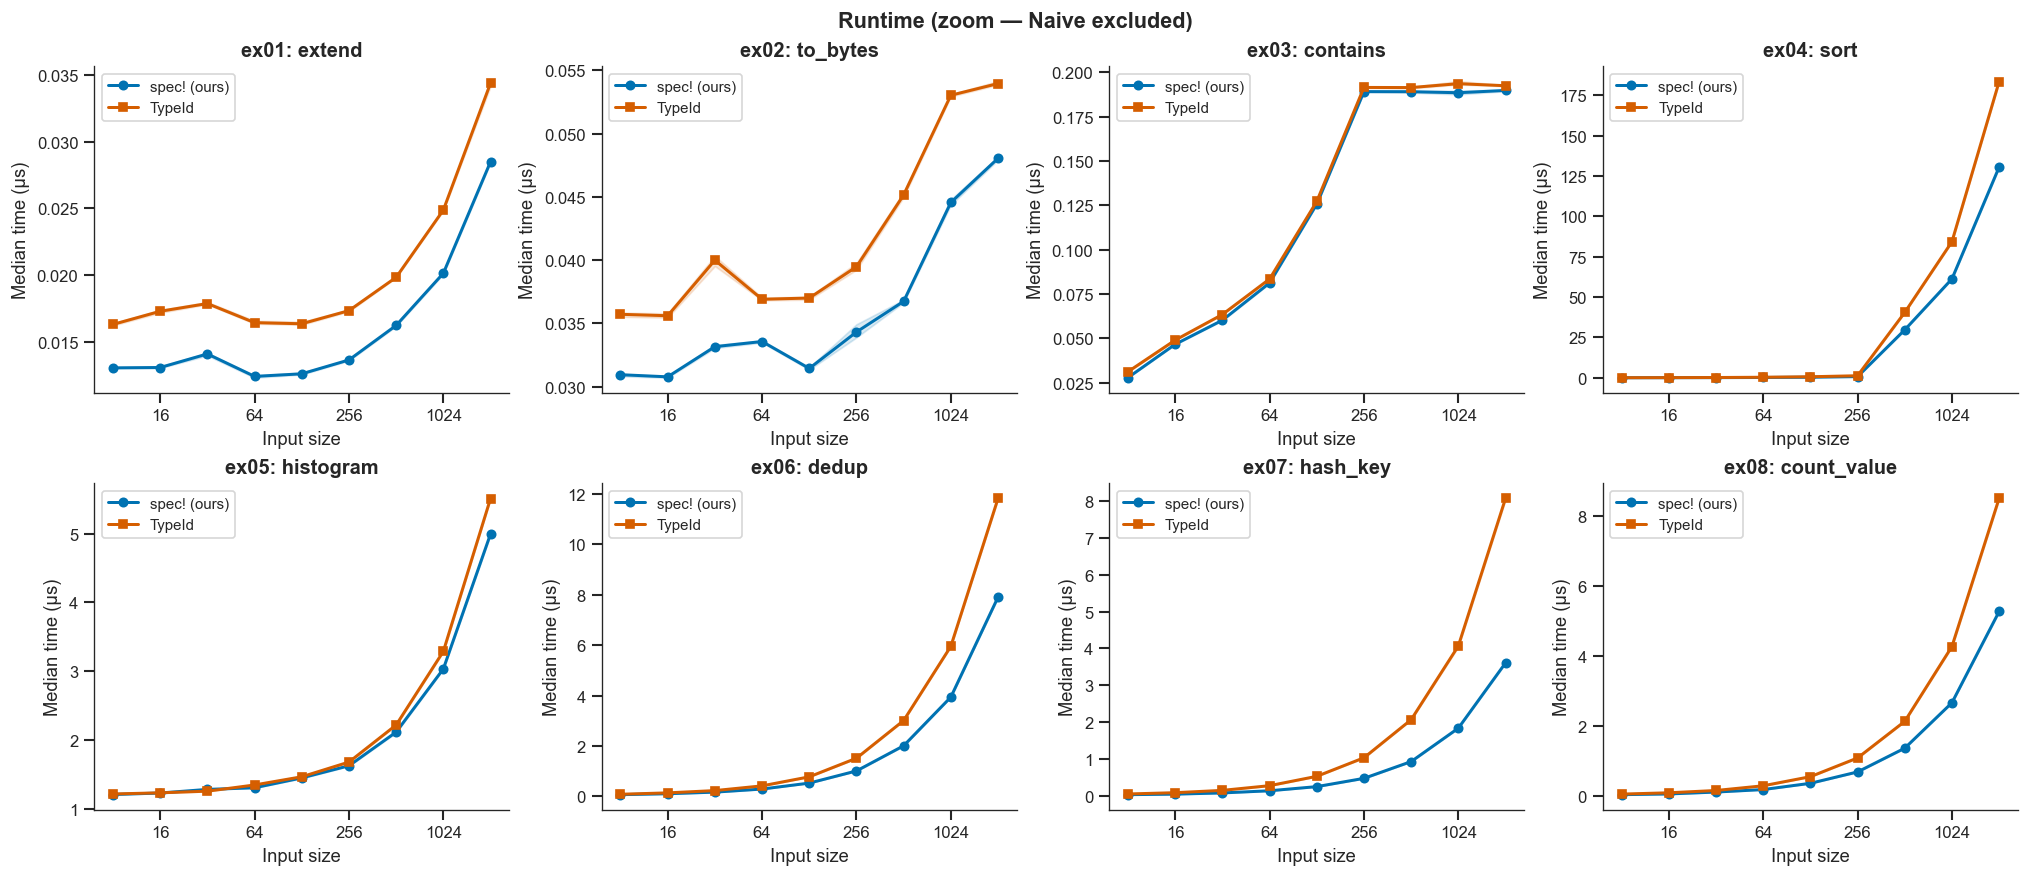

In [4]:
# Zoom — naive excluded to reveal differences among fast approaches
ZOOM_APPROACHES = [a for a in APPROACH_ORDER if a != "naive"]

fig, axes = make_grid(n_ex)

for idx, ex in enumerate(examples):
    ax = axes[idx]
    sub = rt[rt["example"] == ex]
    op = sub["operation"].iloc[0]
    for a in ZOOM_APPROACHES:
        d = sub[sub["approach"] == a].sort_values("size")
        if d.empty:
            continue
        c, m = _color(a), _marker(a)
        ax.plot(d["size"], d["median_us"],
                marker=m, ms=MS, lw=LW, color=c, label=_label(a))
        if has_med_ci:
            ax.fill_between(d["size"],
                            d["median_ci_lower_ns"] / 1000.0,
                            d["median_ci_upper_ns"] / 1000.0,
                            alpha=BAND_A, color=c)
    ax.set_title(f"{ex}: {op}")
    ax.set_xlabel("Input size")
    ax.set_ylabel("Median time (µs)")
    style_log_x(ax)
    ax.legend(fontsize=LEG_FS)

fig.suptitle("Runtime (zoom — Naive excluded)", fontweight="bold", fontsize=13)
finish_grid(fig, axes, n_ex, RESULTS / "runtime_zoom.pdf")
plt.show()

### Speedup of `spec` over each alternative (at largest size)

In [5]:
largest = rt.groupby(["example", "approach"]).apply(
    lambda g: g.loc[g["size"].idxmax()]
).reset_index(drop=True)

spec_times = largest[largest["approach"] == "spec"][["example", "median_ns"]].rename(
    columns={"median_ns": "spec_ns"}
)
merged = largest.merge(spec_times, on="example")
merged["speedup_vs_spec"] = merged["median_ns"] / merged["spec_ns"]

pivot = merged.pivot_table(index="example", columns="approach", values="speedup_vs_spec")
pivot = pivot[[c for c in APPROACH_ORDER if c in pivot.columns]]
pivot.rename(columns=APPROACH_LABELS).style.format("{:.2f}×").background_gradient(
    cmap="RdYlGn", axis=None
).set_caption("Speedup vs spec! at largest input size")

/var/folders/85/w1f_3bln5rzbljrg0v33t7880000gn/T/ipykernel_25603/317917863.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  largest = rt.groupby(["example", "approach"]).apply(


approach,spec! (ours),TypeId,Naive
example,,,
ex01,1.00×,1.21×,226.21×
ex02,1.00×,1.12×,1788.62×
ex03,1.00×,1.01×,2.46×
ex04,1.00×,1.41×,0.89×
ex05,1.00×,1.10×,51.94×
ex06,1.00×,1.50×,13.51×
ex07,1.00×,2.24×,31.44×
ex08,1.00×,1.61×,1.17×


### Runtime with 95% Confidence Intervals

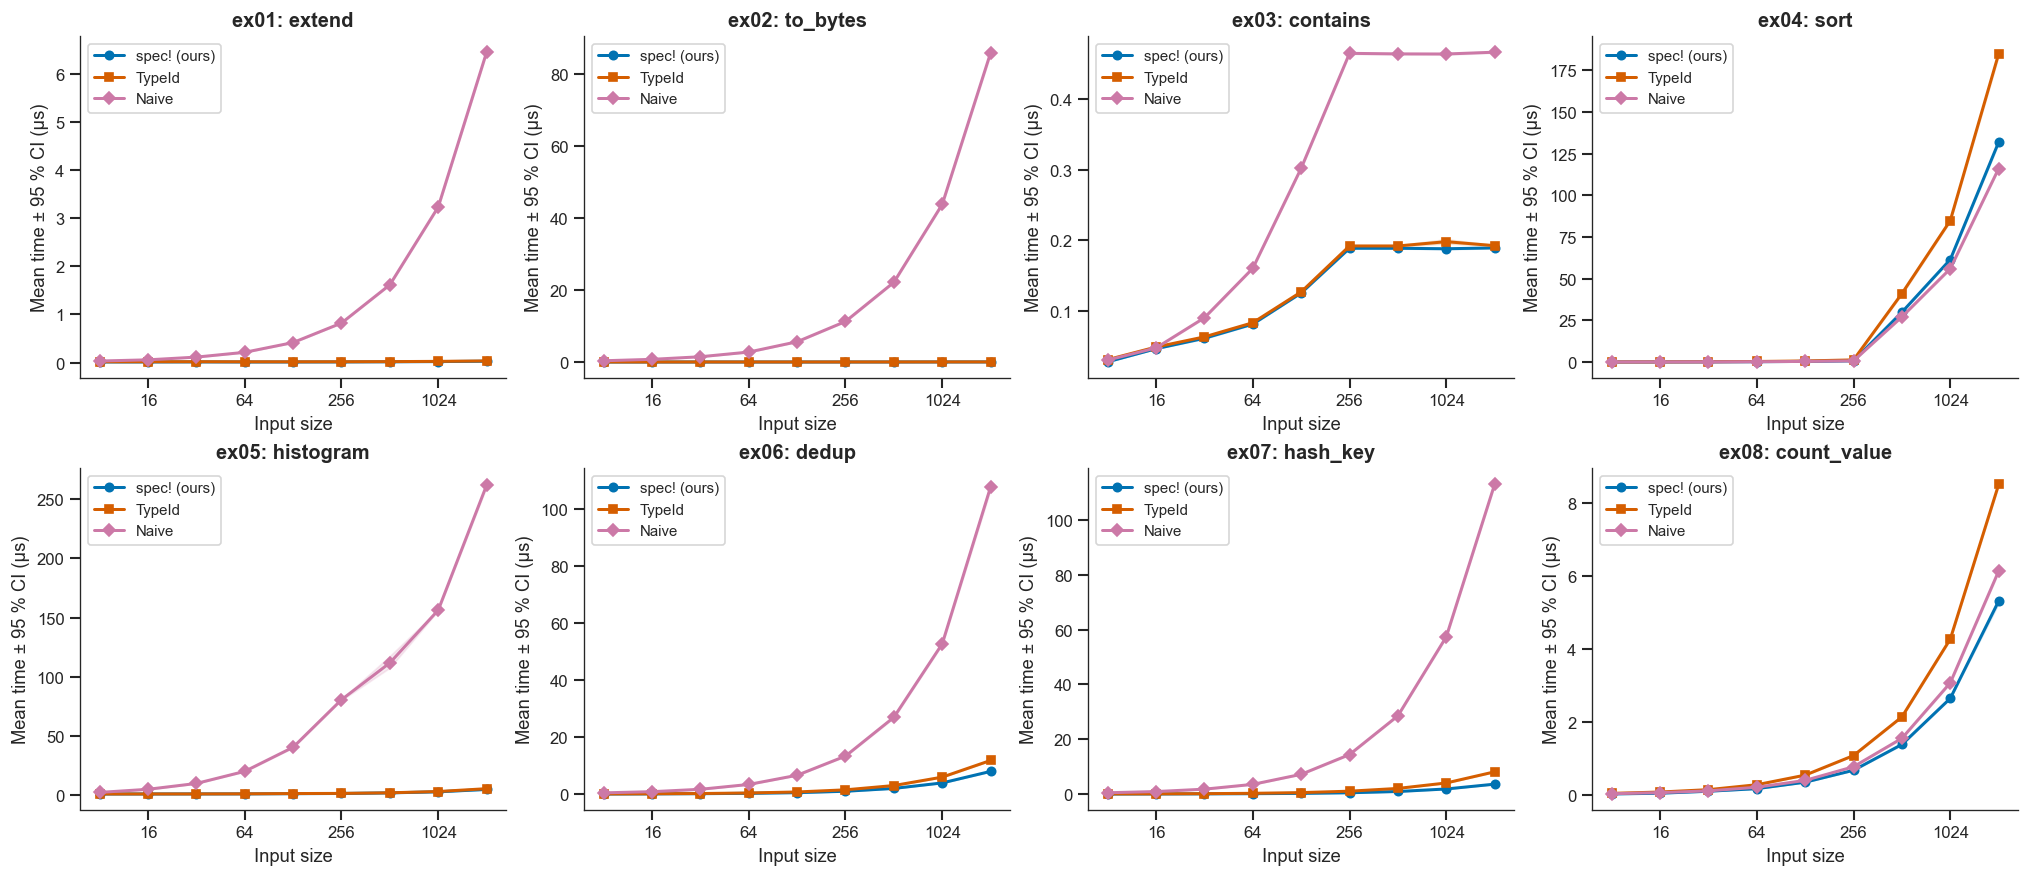

In [6]:
# Mean ± 95 % CI (from Criterion's mean_ci_lower_ns / mean_ci_upper_ns)
has_ci = "mean_ci_lower_ns" in rt.columns and "mean_ci_upper_ns" in rt.columns

if has_ci:
    rt["mean_us"]     = rt["mean_ns"]          / 1000.0
    rt["ci_lower_us"] = rt["mean_ci_lower_ns"] / 1000.0
    rt["ci_upper_us"] = rt["mean_ci_upper_ns"] / 1000.0

    fig, axes = make_grid(n_ex)

    for idx, ex in enumerate(examples):
        ax = axes[idx]
        sub = rt[rt["example"] == ex]
        op = sub["operation"].iloc[0]
        for a in APPROACH_ORDER:
            d = sub[sub["approach"] == a].sort_values("size")
            if d.empty:
                continue
            c, m = _color(a), _marker(a)
            ax.plot(d["size"], d["mean_us"],
                    marker=m, ms=MS, lw=LW, color=c, label=_label(a))
            ax.fill_between(d["size"], d["ci_lower_us"], d["ci_upper_us"],
                            alpha=BAND_A, color=c)
        ax.set_title(f"{ex}: {op}")
        ax.set_xlabel("Input size")
        ax.set_ylabel("Mean time ± 95 % CI (µs)")
        style_log_x(ax)
        ax.legend(fontsize=LEG_FS)

    finish_grid(fig, axes, n_ex, RESULTS / "runtime_ci.pdf")
    plt.show()
else:
    print("CI columns not found — re-run collect_metrics.py with the updated script.")

### Measurement Stability (Coefficient of Variation)

The coefficient of variation (CV = std_dev / mean) shows how noisy each measurement is.
Lower is better: CV < 1% is excellent, 1–5% is acceptable, > 5% suggests instability.

/var/folders/85/w1f_3bln5rzbljrg0v33t7880000gn/T/ipykernel_25603/312580852.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  largest_full = rt.groupby(["example", "approach"]).apply(


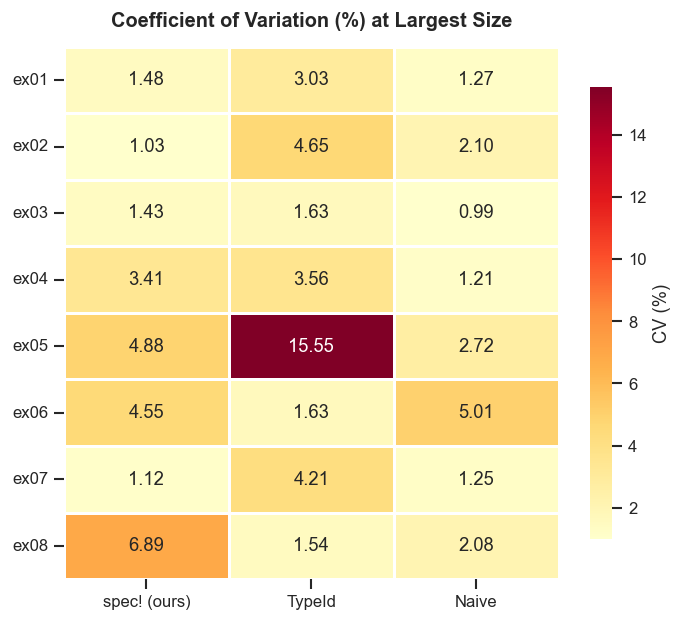

In [7]:
# CV % heatmap at largest input size
has_std = "std_dev_ns" in rt.columns

if has_std:
    largest_full = rt.groupby(["example", "approach"]).apply(
        lambda g: g.loc[g["size"].idxmax()]
    ).reset_index(drop=True)
    largest_full["cv_pct"] = (largest_full["std_dev_ns"] / largest_full["mean_ns"]) * 100.0

    cv_pivot = largest_full.pivot_table(index="example", columns="approach", values="cv_pct")
    cv_pivot = cv_pivot[[c for c in APPROACH_ORDER if c in cv_pivot.columns]]
    cv_pivot = cv_pivot.rename(columns=APPROACH_LABELS)

    fig, ax = plt.subplots(figsize=(6, max(4, len(cv_pivot) * 0.55 + 1)))
    sns.heatmap(cv_pivot, annot=True, fmt=".2f", cmap="YlOrRd",
                ax=ax, linewidths=0.8, linecolor="white",
                annot_kws={"fontsize": 11, "fontweight": "medium"},
                cbar_kws={"label": "CV (%)", "shrink": 0.85})
    ax.set_title("Coefficient of Variation (%) at Largest Size",
                 fontweight="bold", pad=12)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
    sns.despine(ax=ax, left=True, bottom=True)
    fig.tight_layout()
    fig.savefig(RESULTS / "cv_heatmap.pdf", **SAVE_KW)
    plt.show()
else:
    print("std_dev_ns column not found — re-run collect_metrics.py with the updated script.")

### Slope vs Mean Estimate

Criterion computes a *slope* via linear regression over (iterations, time), which is more robust than the arithmetic mean against outliers.
Large divergence between slope and mean suggests measurement noise or non-linear scaling.

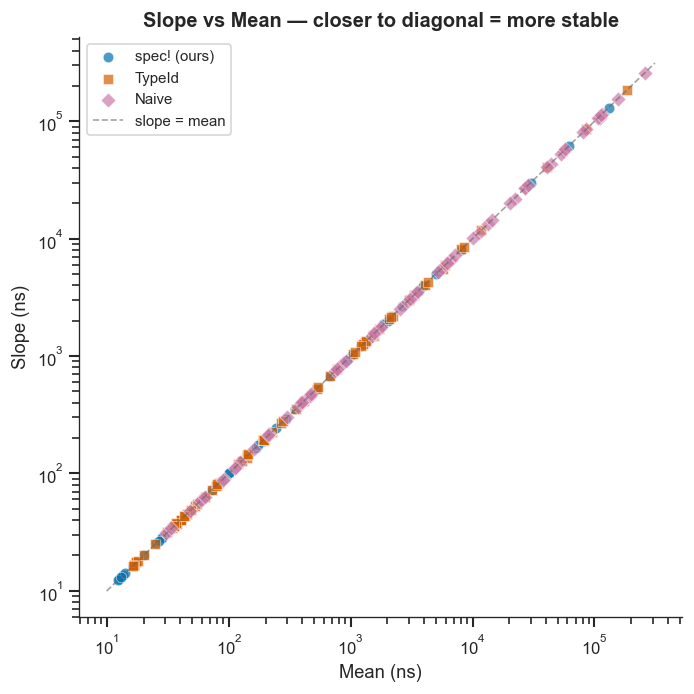

approach,spec! (ours),TypeId,Naive
example,,,
ex01,0.131 %,0.193 %,0.083 %
ex02,0.000 %,0.745 %,0.400 %
ex03,0.141 %,0.369 %,0.171 %
ex04,0.822 %,0.431 %,0.095 %
ex05,0.578 %,2.338 %,0.887 %
ex06,0.474 %,0.009 %,0.989 %
ex07,0.604 %,0.006 %,0.230 %
ex08,0.231 %,0.222 %,0.174 %


In [8]:
# Slope vs Mean — points near diagonal = stable measurements
has_slope = "slope_ns" in rt.columns

if has_slope:
    rt_valid = rt.dropna(subset=["slope_ns", "mean_ns"])

    fig, ax = plt.subplots(figsize=(6, 6))
    for a in APPROACH_ORDER:
        d = rt_valid[rt_valid["approach"] == a]
        if d.empty:
            continue
        ax.scatter(d["mean_ns"], d["slope_ns"],
                   label=_label(a), alpha=0.7, s=40,
                   marker=_marker(a), color=_color(a),
                   edgecolors="white", linewidths=0.4)

    # Reference diagonal (slope == mean)
    lo = min(rt_valid["mean_ns"].min(), rt_valid["slope_ns"].min()) * 0.8
    hi = max(rt_valid["mean_ns"].max(), rt_valid["slope_ns"].max()) * 1.2
    ax.plot([lo, hi], [lo, hi], color="0.4", ls="--", lw=1, alpha=0.6,
            label="slope = mean")

    ax.set_xlabel("Mean (ns)")
    ax.set_ylabel("Slope (ns)")
    ax.set_title("Slope vs Mean — closer to diagonal = more stable")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.legend(fontsize=LEG_FS, loc="upper left")
    sns.despine(ax=ax)
    fig.tight_layout()
    fig.savefig(RESULTS / "slope_vs_mean.pdf", **SAVE_KW)
    plt.show()

    # Divergence table: |slope − mean| / mean at largest size
    if has_std:
        largest_full["slope_mean_pct"] = (
            (largest_full["slope_ns"] - largest_full["mean_ns"]).abs()
            / largest_full["mean_ns"] * 100
        )
        div_pivot = largest_full.pivot_table(
            index="example", columns="approach", values="slope_mean_pct"
        )
        div_pivot = div_pivot[[c for c in APPROACH_ORDER if c in div_pivot.columns]]
        display(
            div_pivot.rename(columns=APPROACH_LABELS)
            .style.format("{:.3f} %")
            .background_gradient(cmap="YlOrRd", axis=None)
            .set_caption("|slope − mean| / mean (%) at largest size")
        )
else:
    print("slope_ns column not found — re-run collect_metrics.py with the updated script.")

## 2. Compile Time

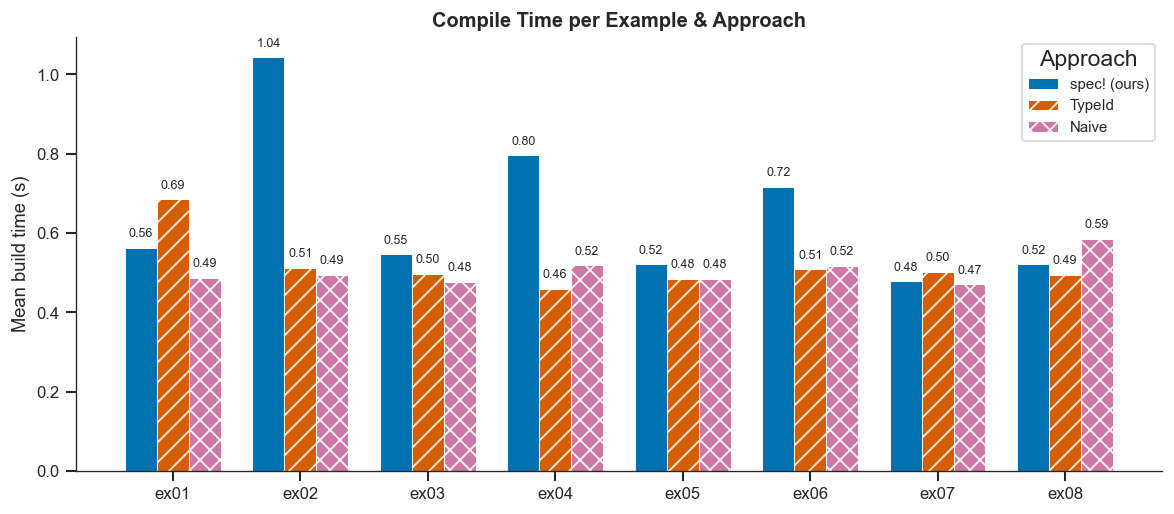

In [9]:
bt = pd.read_csv(RESULTS / "build_time.csv")
bt_avg = bt.groupby(["example", "variant"])["build_time_secs"].mean().reset_index()
bt_avg.columns = ["example", "approach", "mean_build_secs"]

bt_pivot = bt_avg.pivot(index="example", columns="approach", values="mean_build_secs")
bt_pivot = bt_pivot[[c for c in APPROACH_ORDER if c in bt_pivot.columns]]

fig, ax = plt.subplots(figsize=(10, 4.5))
n_groups = len(bt_pivot)
n_bars   = len(bt_pivot.columns)
x        = np.arange(n_groups)
width    = 0.75 / n_bars

for i, col in enumerate(bt_pivot.columns):
    vals = bt_pivot[col].values
    bars = ax.bar(x + i * width - (n_bars - 1) * width / 2,
                  vals, width,
                  label=_label(col),
                  color=_color(col),
                  hatch=APPROACH_HATCHES.get(col, ""),
                  edgecolor="white", linewidth=0.6)
    # Value labels on top
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.02,
                f"{h:.2f}", ha="center", va="bottom", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(bt_pivot.index, rotation=0)
ax.set_ylabel("Mean build time (s)")
ax.set_title("Compile Time per Example & Approach")
ax.legend(fontsize=LEG_FS, title="Approach")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(RESULTS / "build_time.pdf", **SAVE_KW)
plt.show()

## 3. Binary Size

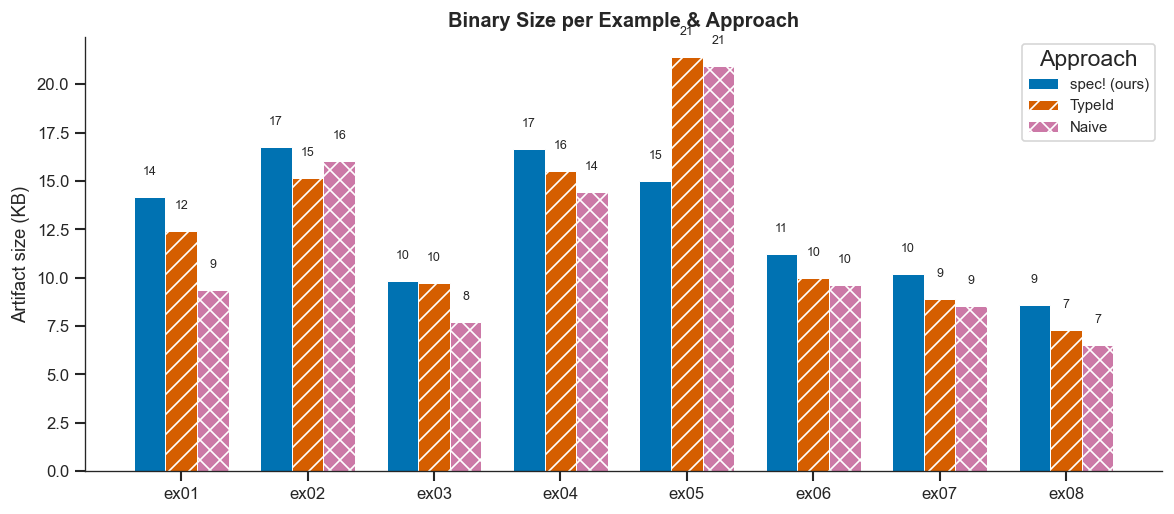

In [10]:
bs = pd.read_csv(RESULTS / "binary_size.csv")
bs.columns = ["example", "approach", "binary_size_bytes", "stripped_size_bytes"]
bs["size_kb"] = bs["binary_size_bytes"] / 1024.0

bs_pivot = bs.pivot(index="example", columns="approach", values="size_kb")
bs_pivot = bs_pivot[[c for c in APPROACH_ORDER if c in bs_pivot.columns]]

fig, ax = plt.subplots(figsize=(10, 4.5))
n_groups = len(bs_pivot)
n_bars   = len(bs_pivot.columns)
x        = np.arange(n_groups)
width    = 0.75 / n_bars

for i, col in enumerate(bs_pivot.columns):
    vals = bs_pivot[col].values
    bars = ax.bar(x + i * width - (n_bars - 1) * width / 2,
                  vals, width,
                  label=_label(col),
                  color=_color(col),
                  hatch=APPROACH_HATCHES.get(col, ""),
                  edgecolor="white", linewidth=0.6)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 1,
                f"{h:.0f}", ha="center", va="bottom", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(bs_pivot.index, rotation=0)
ax.set_ylabel("Artifact size (KB)")
ax.set_title("Binary Size per Example & Approach")
ax.legend(fontsize=LEG_FS, title="Approach")
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(RESULTS / "binary_size.pdf", **SAVE_KW)
plt.show()

## 4. Summary Table

In [11]:
# Combine all metrics into a single summary
summary_parts = []

# Runtime speedup at largest size
if 'pivot' in dir():
    rt_summary = pivot.mean().rename("mean_speedup_vs_spec")
    summary_parts.append(rt_summary)

# Build time overhead vs spec
if 'bt_avg' in dir():
    spec_bt = bt_avg[bt_avg["approach"] == "spec"][["example", "mean_build_secs"]].rename(
        columns={"mean_build_secs": "spec_build"}
    )
    bt_merged = bt_avg.merge(spec_bt, on="example")
    bt_merged["build_ratio"] = bt_merged["mean_build_secs"] / bt_merged["spec_build"]
    bt_ratio = bt_merged.groupby("approach")["build_ratio"].mean()
    summary_parts.append(bt_ratio.rename("mean_build_ratio_vs_spec"))

# Binary size overhead vs spec
if 'bs' in dir():
    spec_bs = bs[bs["approach"] == "spec"][["example", "binary_size_bytes"]].rename(
        columns={"binary_size_bytes": "spec_size"}
    )
    bs_merged = bs.merge(spec_bs, on="example")
    bs_merged["size_ratio"] = bs_merged["binary_size_bytes"] / bs_merged["spec_size"]
    bs_ratio = bs_merged.groupby("approach")["size_ratio"].mean()
    summary_parts.append(bs_ratio.rename("mean_size_ratio_vs_spec"))

if summary_parts:
    summary = pd.concat(summary_parts, axis=1)
    summary = summary.loc[[a for a in APPROACH_ORDER if a in summary.index]]
    summary = summary.rename(index=APPROACH_LABELS)
    summary.style.format("{:.2f}").background_gradient(
        cmap="RdYlGn_r", axis=0
    ).set_caption("Summary — ratios vs spec! (values > 1 = worse)")